# V4: Mini BERT + سابقهٔ کاربر، دقیقاً روی splitهای V2

در Colab با T4، سلول‌ها را از ابتدا اجرا کنید. **مسیر اجرای V2 در تنظیمات را بررسی کنید.** این نسخه فایل‌های split ذخیره‌شدهٔ V2 را بارگذاری می‌کند و عضویت و ترتیب ردیف‌ها، fingerprint داده و summary را بررسی می‌کند. بنابراین نصف کل داده و نسبت ۷۰/۱۵/۱۵ همان V2 باقی می‌ماند. split تازه ساخته نمی‌شود.

ورودی متن همان V2 است: review کوتاه فقط reviewText؛ review بلند شامل summary در ابتدا و سپس ۱۹۲ توکن اول و ۶۴ توکن آخر با احتساب special tokenها، dynamic padding مضرب ۸. stopword حذف نمی‌شود. Mini BERT با ۴ لایه، hidden size=256 و ۴ سر attention کاملاً fine-tune می‌شود؛ batch=128، نرخ یادگیری 2e-5، حداکثر ۴ epoch، patience=2 و معیار انتخاب Micro-F1 حفظ می‌شوند.

دو ویژگی جدید عبارت‌اند از میانگین امتیاز و تعداد نظرات همان کاربر در **روزهای اکیداً قدیمی‌تر و فقط از trainِ V2**. کل train اصلی، نصف استفاده‌نشده، validation و آزمون داخلی منبع history نیستند. برای کاربر بدون سابقه، میانگین جای‌نگهدار ۳ و تعداد صفر است؛ اثر history دقیقاً صفر می‌شود. تاریخ یا شناسهٔ نامعتبر نیز history را غیرفعال می‌کند. ترتیب زمانی فقط شرط محاسبهٔ history است، نه روش تقسیم تصادفی داده.

ترکیب احتمالات: `p = (1-alpha_effective)*p_text + alpha_effective*p_history`؛ مقدار `alpha_effective = alpha_cap * n/(n+k) * sigmoid(gate)` است. k مثبت و gate یادگرفتنی‌اند؛ k با ۱۰ شروع می‌شود. سقف alpha یک hyperparameter است، نه وزن مؤثر ثابت هر نمونه. با `alpha_as_hyperparameter=False` تنها سقف ۲۰٪ آموزش داده می‌شود؛ با True سه اجرای مستقل با سقف‌های **۳۰٪، ۲۰٪ و ۱۰٪** انجام می‌شود. هر اجرا از checkpoint پیش‌آموخته و seed یکسان شروع می‌کند. بهترین checkpoint هر اجرا و سپس بهترین سقف با Micro-F1 validation انتخاب می‌شود؛ در تساوی سقف کوچک‌تر انتخاب می‌شود. هزینهٔ حالت True تقریباً سه آموزش است؛ داده فقط یک بار توکن‌سازی می‌شود.

آزمون داخلی با RUN_TEST=False خاموش است و فقط پس از تثبیت تصمیم‌ها روی مدل منتخب اجرا می‌شود. test اصلی بدون برچسب در این آزمایش خوانده نمی‌شود. این فایل نتیجهٔ آموزشی از پیش محاسبه‌شده ندارد.


In [3]:
%pip install -q "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" "pandas>=2.2,<4" scikit-learn gdown pyarrow matplotlib


## ۱. تنظیمات و دریافت دادهٔ اصلی


In [4]:
from pathlib import Path
import os, json, hashlib, shutil, time, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from sklearn.model_selection import train_test_split
from transformers import set_seed
from google.colab import drive

SEED = 42
MODEL_NAME = "google/bert_uncased_L-4_H-256_A-4"
MAX_LENGTH = 256
HEAD_TOKENS = 192
TAIL_TOKENS = 64
TRAIN_BATCH_SIZE = 128
GRADIENT_ACCUMULATION_STEPS = 1
EVAL_BATCH_SIZE = 128
EPOCHS = 4
LEARNING_RATE = 2e-5
alpha_as_hyperparameter = False
ALPHA_CAPS = [0.30, 0.20, 0.10] if alpha_as_hyperparameter else [0.20]
RUN_TEST = False  # Enable only after the model-development decisions are final.
# Example: '/content/drive/MyDrive/amazon_sentiment/half_data_baselines/OLD_RUN_ID'
BASELINE_RUN_DIR = '/content/drive/MyDrive/amazon_sentiment/experiments_256/20261104_160755_670535'
REUSE_SPLITS_DIR = None  # Alternatively, set the previous run's 'splits' directory.
if BASELINE_RUN_DIR is not None and REUSE_SPLITS_DIR is None:
    REUSE_SPLITS_DIR = str(Path(BASELINE_RUN_DIR)/'splits')

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU in Colab.")
drive.mount('/content/drive')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
LOCAL_RUN_DIR = Path('/content/amazon_history_runs') / RUN_ID
RUN_DIR = Path('/content/drive/MyDrive/amazon_sentiment/experiments_history') / RUN_ID
SPLITS_DIR = RUN_DIR / 'splits'
CHECKPOINT_DIR = LOCAL_RUN_DIR / 'checkpoints'
for directory in [LOCAL_RUN_DIR, RUN_DIR, SPLITS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('Results:', RUN_DIR)

print('Physical training batch:', TRAIN_BATCH_SIZE)
print('Effective training batch:', TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS)
if 'T4' not in torch.cuda.get_device_name(0):
    print('This run was configured for T4; the detected GPU is recorded in the results.')

BASELINE_RUN_DIR=Path(BASELINE_RUN_DIR)
if not (BASELINE_RUN_DIR/'splits'/'split_manifest.json').exists():
    raise FileNotFoundError('Set BASELINE_RUN_DIR to your saved V2 run containing splits/split_manifest.json.')
REUSE_SPLITS_DIR=str(BASELINE_RUN_DIR/'splits')
baseline_config=json.loads((BASELINE_RUN_DIR/'experiment_config.json').read_text())
expected={'model':MODEL_NAME,'max_length':MAX_LENGTH,'train_batch':TRAIN_BATCH_SIZE,
          'eval_batch':EVAL_BATCH_SIZE,'gradient_accumulation_steps':1,'epochs_max':EPOCHS,
          'seed':SEED,'selection_metric':'micro_f1','early_stopping_patience':2}
for key,value in expected.items():
    if baseline_config.get(key)!=value: raise ValueError(f'V2 configuration differs: {key}')
for key,value in {'learning_rate':LEARNING_RATE,'weight_decay':0.01,'warmup_ratio':0.06,
                  'lr_scheduler_type':'linear','fp16':True,'bf16':False,'optim':'adamw_torch'}.items():
    if baseline_config['training_args'].get(key)!=value: raise ValueError(f'V2 training differs: {key}')
print('Alpha caps:',ALPHA_CAPS)


Mounted at /content/drive
GPU: Tesla T4
Results: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545
Physical training batch: 128
Effective training batch: 128
Alpha caps: [0.2]


In [5]:
from pathlib import Path
import gdown

DATA_DIR = Path("/content/amazon_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

FILE_ID = "1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW"

# Preserve the original filename and extension.
downloaded_path = gdown.download(
    id=FILE_ID,
    output=str(DATA_DIR) + "/",
    quiet=False,
)

if downloaded_path is None:
    raise RuntimeError("Download failed. Check the file's sharing permissions.")

data_path = Path(downloaded_path)

print("Filename:", data_path.name)
print(f"File size: {data_path.stat().st_size / (1024**2):,.1f} MB")


Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=d8ed659f-60d0-42e8-a85e-21e777745970
To: /content/amazon_data/train_data.csv
100%|██████████| 635M/635M [00:08<00:00, 78.2MB/s]

Filename: train_data.csv
File size: 605.2 MB


In [6]:
import gzip
import json
import zipfile

import pandas as pd
from IPython.display import display

KEEP_COLUMNS = ["reviewText", "summary", "overall", "reviewerID", "unixReviewTime", "reviewTime"]


def read_reviews(stream, filename):
    name = filename.lower()

    if name.endswith(".csv"):
        return pd.read_csv(
            stream,
            usecols=lambda column: column in KEEP_COLUMNS,
        )

    if name.endswith((".json", ".jsonl", ".ndjson")):
        # Inspect the first line to distinguish JSON Lines from a JSON array.
        first_line = stream.readline().strip()
        stream.seek(0)

        if first_line.startswith(b"["):
            frame = pd.read_json(stream)
            return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

        try:
            first_record = json.loads(first_line)
            is_json_lines = isinstance(first_record, dict)
        except json.JSONDecodeError:
            is_json_lines = False

        if is_json_lines:
            # Read in chunks to reduce temporary memory usage.
            chunks = pd.read_json(stream, lines=True, chunksize=50_000)
            frames = [
                chunk.loc[:, chunk.columns.intersection(KEEP_COLUMNS)]
                for chunk in chunks
            ]
            return pd.concat(frames, ignore_index=True)

        frame = pd.read_json(stream)
        return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

    raise ValueError(f"Unsupported file format: {filename}")


if zipfile.is_zipfile(data_path):
    with zipfile.ZipFile(data_path) as archive:
        candidates = [
            name for name in archive.namelist()
            if not name.startswith("__MACOSX/")
            and name.lower().endswith((".csv", ".json", ".jsonl", ".ndjson"))
        ]

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one data file inside ZIP. Found: {candidates}"
            )

        with archive.open(candidates[0]) as stream:
            df = read_reviews(stream, candidates[0])

elif data_path.name.lower().endswith(".gz"):
    with gzip.open(data_path, "rb") as stream:
        df = read_reviews(stream, data_path.stem)

else:
    with data_path.open("rb") as stream:
        df = read_reviews(stream, data_path.name)

required_columns = {"reviewText", "overall"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Number of reviews: {len(df):,}")
print("Loaded columns:", df.columns.tolist())
display(df.head())

if 'reviewerID' not in df.columns or not {'unixReviewTime','reviewTime'}.intersection(df.columns):
    raise ValueError('Input needs reviewerID and a review timestamp column.')


Number of reviews: 838,944
Loaded columns: ['overall', 'reviewTime', 'reviewerID', 'reviewText', 'summary', 'unixReviewTime']


,overall,reviewTime,reviewerID,reviewText,summary,unixReviewTime
0,2,2016-11-11,A2OSUEZJIN7BI,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400
1,5,2016-06-06,A2NETQRG6JHIG7,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200
2,4,2016-03-10,A12JHGROAX49G7,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000
3,5,2016-01-14,A1KV65E2TMMG6F,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600
4,5,2016-10-20,A280POPEWI0NSA,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600


## ۲. بازیابی دقیق splitهای V2 و ساخت بانک سابقه


In [7]:
import numpy as np
import pandas as pd

def history_days(frame):
    missing=pd.Series(pd.NaT,index=frame.index,dtype='datetime64[ns, UTC]')
    unix=missing.copy();cal=missing.copy()
    if 'unixReviewTime' in frame:
        unix=pd.to_datetime(pd.to_numeric(frame['unixReviewTime'],errors='coerce'),unit='s',errors='coerce',utc=True)
    if 'reviewTime' in frame:
        cal=pd.to_datetime(frame['reviewTime'],format='mixed',errors='coerce',utc=True)
    return unix.fillna(cal).dt.floor('D')

def normalized_users(values):
    return values.astype('string').str.strip().replace('',pd.NA)

def build_history_bank(reference):
    good=reference.dropna(subset=['user','day']).copy()
    good=good[good['overall'].isin([1,2,3,4,5])]
    bank=good.groupby(['user','day'],as_index=False).agg(
        day_count=('overall','size'),day_sum=('overall','sum')).sort_values(['user','day'])
    bank['past_count']=bank.groupby('user')['day_count'].cumsum().astype('int64')
    bank['past_sum']=bank.groupby('user')['day_sum'].cumsum()
    return bank[['user','day','past_count','past_sum']].reset_index(drop=True)

def attach_history(query,bank):
    # query labels are deliberately never read.
    base=query[['source_row_id','user','day']].reset_index(drop=True).copy()
    base['_position']=np.arange(len(base))
    known=base.dropna(subset=['user','day'])
    if len(known) and len(bank):
        right=bank.rename(columns={'day':'matched_day'})
        matches=pd.merge_asof(known.sort_values('day'),right.sort_values('matched_day'),
            left_on='day',right_on='matched_day',by='user',direction='backward',allow_exact_matches=False)
        assert (matches.loc[matches['matched_day'].notna(),'matched_day']<matches.loc[matches['matched_day'].notna(),'day']).all()
        small=matches[['_position','past_count','past_sum']]
        base=base.merge(small,on='_position',how='left',validate='one_to_one').sort_values('_position')
    else:
        base['past_count']=0;base['past_sum']=0.0
    count=base['past_count'].fillna(0).to_numpy(dtype='int64')
    sums=base['past_sum'].fillna(0).to_numpy(dtype='float64')
    mean=np.divide(sums,count,out=np.full(len(base),3.0),where=count>0)
    result=query.reset_index(drop=True).copy()
    result['past_count']=count;result['past_mean']=mean.astype('float32')
    return result


In [8]:
if 'summary' not in df.columns:
    raise ValueError("The input file must include 'summary' for this experiment.")
# Keep the BASELINE fingerprint independent of the newly added input feature.
metadata_by_id=df[['reviewerID']].copy()
metadata_by_id['day']=history_days(df)
metadata_by_id['user']=normalized_users(df['reviewerID'])
summary_by_id = df['summary'].fillna('').astype(str).str.strip().reset_index(drop=True)
data = df[['reviewText', 'overall']].copy()
data['source_row_id'] = np.arange(len(data), dtype=np.int64)
data['overall'] = pd.to_numeric(data['overall'], errors='coerce')
data['reviewText'] = data['reviewText'].astype('string').str.strip()
valid = (data['overall'].isin([1,2,3,4,5]) & data['reviewText'].notna()
         & data['reviewText'].ne('')).fillna(False)
data = data.loc[valid].copy()
data['overall'] = data['overall'].astype('int64')
data['labels'] = data['overall'] - 1
data = data.reset_index(drop=True)
# Include cleaned text, labels and row identity in the data fingerprint.
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(data, index=False).values.tobytes()
).hexdigest()

if REUSE_SPLITS_DIR is None:
    selected_df, _ = train_test_split(
        data, train_size=0.5, stratify=data['labels'], random_state=SEED)
    train_df, remaining = train_test_split(
        selected_df, test_size=0.30,
        stratify=selected_df['labels'], random_state=SEED)
    val_df, test_df = train_test_split(
        remaining, test_size=0.50, stratify=remaining['labels'], random_state=SEED)
else:
    old_dir = Path(REUSE_SPLITS_DIR)
    previous = json.loads((old_dir/'split_manifest.json').read_text())
    assert previous['data_fingerprint'] == fingerprint, 'Input data changed.'
    assert previous['seed'] == SEED, 'Split seed changed.'
    train_df, val_df, test_df = [pd.read_parquet(old_dir/f'{s}.parquet')
                                for s in ['train','validation','test']]
    # Verify saved rows against current input before attaching summaries.
    current = data.set_index('source_row_id')
    for frame in [train_df, val_df, test_df]:
        saved_ids = frame['source_row_id'].to_numpy()
        expected = current.loc[saved_ids]
        assert np.array_equal(expected['labels'].to_numpy(), frame['labels'].to_numpy())
        assert np.array_equal(expected['reviewText'].to_numpy(), frame['reviewText'].to_numpy())
    selected_df = pd.concat([train_df,val_df,test_df], ignore_index=True)

# Copies avoid chained assignment and preserve the stored row order.
train_df, val_df, test_df = [f.copy() for f in [train_df, val_df, test_df]]
for frame in [train_df, val_df, test_df]:
    ids=frame['source_row_id'].to_numpy()
    frame['summary'] = summary_by_id.iloc[ids].to_numpy()
    frame['user']=metadata_by_id['user'].iloc[ids].to_numpy()
    frame['user']=frame['user'].astype('string')
    frame['day']=pd.to_datetime(metadata_by_id['day'].iloc[ids].to_numpy(),utc=True)
split_frames = {'train': train_df, 'validation': val_df, 'test': test_df}
id_sets = [set(f['source_row_id']) for f in split_frames.values()]
assert all(len(ids)==len(frame) for ids,frame in zip(id_sets,split_frames.values()))
assert all(id_sets[i].isdisjoint(id_sets[j]) for i,j in [(0,1),(0,2),(1,2)])
assert sum(map(len,split_frames.values())) == len(data)//2
split_fingerprint = hashlib.sha256(b''.join(
    np.sort(f['source_row_id'].to_numpy(dtype=np.int64)).tobytes()
    for f in split_frames.values())).hexdigest()
for name, frame in split_frames.items():
    frame.reset_index(drop=True).to_parquet(SPLITS_DIR/f'{name}.parquet', index=False)
manifest = {'seed': SEED, 'data_fingerprint':fingerprint,
            'split_fingerprint':split_fingerprint, 'sampling_fraction':0.5,
            'ratios':[0.70,0.15,0.15],
            'sizes':{name:len(f) for name,f in split_frames.items()},
            'summary_fingerprint': hashlib.sha256(pd.util.hash_pandas_object(
                summary_by_id, index=False).values.tobytes()).hexdigest()}
(SPLITS_DIR/'split_manifest.json').write_text(json.dumps(manifest,indent=2))
def percentages(frame):
    return frame['overall'].value_counts(normalize=True).reindex(range(1,6),fill_value=0)*100
display(pd.DataFrame({'All usable (%)':percentages(data),
                      'Selected half (%)':percentages(selected_df),
                      **{name+' (%)':percentages(f) for name,f in split_frames.items()}}).round(3))
print('Usable:',len(data), '| Selected:',len(selected_df))
print('Sizes:', manifest['sizes'])
print('Reuse these splits:', SPLITS_DIR)
text_sets = {name:set(f['reviewText']) for name,f in split_frames.items()}
duplicate_overlap = {f'{a} vs {b}':len(text_sets[a]&text_sets[b])
    for a,b in [('train','validation'),('train','test'),('validation','test')]}
print('Number of distinct identical texts shared between splits:',duplicate_overlap)
(RUN_DIR/'duplicate_text_overlap.json').write_text(json.dumps(duplicate_overlap,indent=2))
del text_sets, df, data, selected_df, summary_by_id

assert split_fingerprint==baseline_config['split_fingerprint']
assert manifest['summary_fingerprint']==baseline_config['summary_fingerprint']
assert manifest['sizes']==previous['sizes']
history_bank=build_history_bank(train_df)
history_bank.to_parquet(RUN_DIR/'history_bank.parquet',index=False)
train_df,val_df,test_df=[attach_history(frame,history_bank) for frame in [train_df,val_df,test_df]]
split_frames={'train':train_df,'validation':val_df,'test':test_df}
history_policy={'source':'V2 train split only','time_unit':'UTC day','strictly_before':True,
                'unknown_mean_placeholder':3.0,'no_history_alpha':0.0,
                'history_bank_rows':len(history_bank),
                'history_reference_rows':len(train_df),
                'split_fingerprint':split_fingerprint}
(RUN_DIR/'history_policy.json').write_text(json.dumps(history_policy,indent=2))
coverage=[]
for name,frame in split_frames.items():
    coverage.append({'split':name,'rows':len(frame),'history_rows':int(frame.past_count.gt(0).sum()),
        'history_pct':100*frame.past_count.gt(0).mean(),'mean_past_count':frame.past_count.mean(),
        'missing_user_rows':int(frame.user.isna().sum()),'missing_day_rows':int(frame.day.isna().sum())})
    frame[['source_row_id','past_mean','past_count']].to_parquet(RUN_DIR/f'{name}_history_features.parquet',index=False)
coverage=pd.DataFrame(coverage)
coverage.to_csv(RUN_DIR/'history_coverage.csv',index=False);display(coverage)
del metadata_by_id,current,expected


,All usable (%),Selected half (%),train (%),validation (%),test (%)
overall,,,,,
1,9.887,9.887,9.887,9.887,9.889
2,6.765,6.765,6.765,6.766,6.764
3,9.683,9.683,9.683,9.684,9.684
4,18.656,18.656,18.656,18.655,18.657
5,55.008,55.008,55.008,55.009,55.007


Usable: 838944 | Selected: 419472
Sizes: {'train': 293630, 'validation': 62921, 'test': 62921}
Reuse these splits: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/splits
Number of distinct identical texts shared between splits: {'train vs validation': 1732, 'train vs test': 1714, 'validation vs test': 386}


,split,rows,history_rows,history_pct,mean_past_count,missing_user_rows,missing_day_rows
0,train,293630,93281,31.768212,0.719719,0,0
1,validation,62921,20103,31.949588,0.720459,0,0
2,test,62921,19969,31.736622,0.725767,0,0


## ۳. توکن‌سازی یک‌باره و آماده‌سازی batch عددی

عضویت و ترتیب نمونه‌ها در دادهٔ توکن‌شده دقیقاً مطابق splitهاست. تعداد و میانگین به‌صورت دو عدد به مدل داده می‌شوند، نه به‌صورت متن داخل بودجهٔ ۲۵۶ توکنی.


In [9]:
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=False)
assert SPECIAL_TOKENS == 2
assert HEAD_TOKENS + TAIL_TOKENS == MAX_LENGTH
CONTENT_LIMIT = MAX_LENGTH - SPECIAL_TOKENS
HEAD_CONTENT = HEAD_TOKENS - 1  # [CLS] belongs to the head segment.
TAIL_CONTENT = TAIL_TOKENS - 1  # [SEP] belongs to the tail segment.

PREPROCESSING_CONFIG = {
    'max_length':MAX_LENGTH, 'head_tokens_with_cls':HEAD_TOKENS,
    'tail_tokens_with_sep':TAIL_TOKENS, 'short_input':'reviewText_only',
    'long_input':'summary + single_space + reviewText',
    'long_review_threshold_content_tokens':CONTENT_LIMIT,
    'dynamic_padding':True, 'pad_to_multiple_of':8,
}

def select_content_ids(review_ids, combined_ids=None):
    # Operate on token IDs; decoding/re-encoding can change token boundaries.
    if len(review_ids) <= CONTENT_LIMIT:
        return list(review_ids)
    if combined_ids is None or len(combined_ids) <= CONTENT_LIMIT:
        raise ValueError('A long review requires the complete combined token IDs.')
    return list(combined_ids[:HEAD_CONTENT]) + list(combined_ids[-TAIL_CONTENT:])

def wrap_content_ids(content_ids):
    input_ids = tokenizer.build_inputs_with_special_tokens(content_ids)
    token_type_ids = tokenizer.create_token_type_ids_from_sequences(content_ids)
    assert len(input_ids) <= MAX_LENGTH
    return {'input_ids':input_ids, 'attention_mask':[1]*len(input_ids),
            'token_type_ids':token_type_ids}

def tokenize_batch(batch):
    reviews = [str(text).strip() for text in batch['reviewText']]
    summaries = [str(text).strip() for text in batch['summary']]
    review_ids = tokenizer(reviews, add_special_tokens=False, truncation=False,
                           padding=False, verbose=False)['input_ids']
    # Only long reviews need a second tokenization with their summaries.
    long_indices = [i for i, ids in enumerate(review_ids) if len(ids)>CONTENT_LIMIT]
    combined_by_index = {}
    if long_indices:
        combined = [(summaries[i]+' '+reviews[i]).strip() for i in long_indices]
        combined_ids = tokenizer(combined, add_special_tokens=False, truncation=False,
                                 padding=False, verbose=False)['input_ids']
        combined_by_index = dict(zip(long_indices, combined_ids))
    output = {'input_ids':[], 'attention_mask':[], 'token_type_ids':[]}
    for i, ids in enumerate(review_ids):
        example = wrap_content_ids(select_content_ids(ids, combined_by_index.get(i)))
        for key in output:
            output[key].append(example[key])
    return output

raw_datasets = DatasetDict({name:Dataset.from_pandas(
    frame[['reviewText','summary','labels','past_mean','past_count']],preserve_index=False)
    for name,frame in [('train',train_df),('validation',val_df)]})
tokenized_datasets = raw_datasets.map(
    tokenize_batch, batched=True, batch_size=256,
    remove_columns=['reviewText','summary'], desc='Tokenizing 256-token head-tail inputs')
text_collator=DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
class HistoryCollator:
    def __call__(self,examples):
        history=torch.tensor([[float(e.get('past_mean',3.0)),float(e.get('past_count',0))] for e in examples],dtype=torch.float32)
        examples=[{k:v for k,v in e.items() if k not in ['past_mean','past_count']} for e in examples]
        batch=text_collator(examples)
        batch['history_features']=history
        return batch

data_collator=HistoryCollator()
print(tokenized_datasets)

# Boundary checks use the actual tokenizer; these do not train the model.
assert select_content_ids(list(range(254)), [999]*400) == list(range(254))
synthetic_review = list(range(255))
synthetic_combined = list(range(500))
selected = select_content_ids(synthetic_review, synthetic_combined)
assert selected == synthetic_combined[:191] + synthetic_combined[-63:]
assert len(wrap_content_ids(selected)['input_ids']) == 256
example_batch = tokenize_batch({
    'reviewText':['good product', 'good '*254, 'good '*255, 'bad '*400],
    'summary':['ignored summary', 'ignored summary', 'excellent', ''],
})
lengths = [len(ids) for ids in example_batch['input_ids']]
assert lengths[0] < 256 and lengths[1:] == [256,256,256]
assert example_batch['input_ids'][0] == tokenizer('good product')['input_ids']
expected_combined = tokenizer('excellent '+'good '*255,
                              add_special_tokens=False)['input_ids']
assert example_batch['input_ids'][2] == tokenizer.build_inputs_with_special_tokens(
    expected_combined[:191]+expected_combined[-63:])
padded = data_collator([{key:value[i] for key,value in example_batch.items()}
                        for i in range(4)])
assert padded['input_ids'].shape == (4,256)
assert padded['attention_mask'].sum(dim=1).tolist() == lengths
print('Token selection, boundary cases and dynamic-padding checks passed.')
del padded


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Tokenizing 256-token head-tail inputs:   0%|          | 0/293630 [00:00<?, ? examples/s]

Tokenizing 256-token head-tail inputs:   0%|          | 0/62921 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'past_mean', 'past_count', 'input_ids', 'attention_mask', 'token_type_ids'],
        num_rows: 293630
    })
    validation: Dataset({
        features: ['labels', 'past_mean', 'past_count', 'input_ids', 'attention_mask', 'token_type_ids'],
        num_rows: 62921
    })
})
Token selection, boundary cases and dynamic-padding checks passed.


## ۴. مدل ترکیبی و امکان ذخیره و بارگذاری مجدد


In [10]:
HISTORY_MODEL_SOURCE = '''import math
import torch
from torch import nn
from torch.nn import functional as F
from transformers import BertConfig, BertModel, BertPreTrainedModel
from transformers.modeling_outputs import SequenceClassifierOutput

class HistoryBertConfig(BertConfig):
    model_type='bert_user_history'
    def __init__(self, alpha_cap=0.2, history_hidden=16, k_initial=10.0, **kwargs):
        super().__init__(**kwargs)
        if not 0<=alpha_cap<=1: raise ValueError('alpha_cap must be in [0,1]')
        self.alpha_cap=float(alpha_cap)
        self.history_hidden=int(history_hidden)
        self.k_initial=float(k_initial)

class HistoryBertForSequenceClassification(BertPreTrainedModel):
    config_class=HistoryBertConfig
    def __init__(self,config):
        super().__init__(config)
        self.num_labels=config.num_labels
        self.bert=BertModel(config)
        rate=config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob
        self.dropout=nn.Dropout(rate)
        self.classifier=nn.Linear(config.hidden_size,config.num_labels)
        self.history_head=nn.Sequential(nn.Linear(2,config.history_hidden),nn.ReLU(),nn.Linear(config.history_hidden,config.num_labels))
        self.history_gate=nn.Sequential(nn.Linear(config.hidden_size+2,config.history_hidden),nn.ReLU(),nn.Linear(config.history_hidden,1))
        self.raw_k=nn.Parameter(torch.tensor(math.log(math.expm1(config.k_initial))))
        self.post_init()
        nn.init.constant_(self.history_gate[-1].bias,-1.0)

    def mix_with_history(self,pooled,text_logits,history_features):
        values=history_features.float()
        mean=values[:,0].clamp(1,5)
        count=values[:,1].clamp_min(0)
        normalized=torch.stack([(mean-3)/2,torch.log1p(count)/math.log(101)],dim=-1)
        history_logits=self.history_head(normalized.to(pooled.dtype))
        gate=self.history_gate(torch.cat([pooled,normalized.to(pooled.dtype)],dim=-1)).squeeze(-1).float().sigmoid()
        k=F.softplus(self.raw_k.float())+1e-6
        alpha=self.config.alpha_cap*(count/(count+k))*gate
        # All probability computations stay FP32 under autocast, including NLL.
        text_p=F.softmax(text_logits.float(),dim=-1)
        history_p=F.softmax(history_logits.float(),dim=-1)
        p=(1-alpha[:,None])*text_p+alpha[:,None]*history_p
        return p.clamp_min(1e-12).log(),alpha

    def forward(self,input_ids=None,attention_mask=None,token_type_ids=None,
                history_features=None,labels=None,return_dict=None):
        encoded=self.bert(input_ids=input_ids,attention_mask=attention_mask,
                          token_type_ids=token_type_ids,return_dict=True)
        pooled=encoded.pooler_output
        text_logits=self.classifier(self.dropout(pooled))
        if history_features is None:
            history_features=pooled.new_zeros((pooled.shape[0],2))
            history_features[:,0]=3
        log_p,_=self.mix_with_history(pooled,text_logits,history_features)
        loss=F.nll_loss(log_p,labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss,logits=log_p)
'''
MODEL_CODE_PATH=LOCAL_RUN_DIR/'history_model.py'
MODEL_CODE_PATH.write_text(HISTORY_MODEL_SOURCE)
import sys, importlib.util
spec=importlib.util.spec_from_file_location('history_model',MODEL_CODE_PATH)
history_module=importlib.util.module_from_spec(spec)
sys.modules['history_model']=history_module
spec.loader.exec_module(history_module)
HistoryBertConfig=history_module.HistoryBertConfig
HistoryBertForSequenceClassification=history_module.HistoryBertForSequenceClassification


In [11]:
def make_model(alpha_cap):
    set_seed(SEED)
    text_model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,num_labels=5,id2label={i:str(i+1) for i in range(5)},label2id={str(i+1):i for i in range(5)})
    config_values=text_model.config.to_dict()
    config_values.pop('model_type',None)
    config=HistoryBertConfig(alpha_cap=alpha_cap,k_initial=10.0,history_hidden=16,**config_values)
    model=HistoryBertForSequenceClassification(config)
    incompatible=model.load_state_dict(text_model.state_dict(),strict=False)
    assert not incompatible.unexpected_keys
    assert set(incompatible.missing_keys)=={name for name in model.state_dict() if name.startswith(('history_head.','history_gate.','raw_k'))}
    for key,value in text_model.state_dict().items():
        assert torch.equal(model.state_dict()[key],value)
    del text_model
    return model

# Local smoke test with a tiny random BERT: no training data or network access.
from transformers import BertConfig
from torch.nn import functional as F
import tempfile
with tempfile.TemporaryDirectory() as smoke_dir:
    tiny_config=HistoryBertConfig(vocab_size=32,hidden_size=16,num_hidden_layers=1,
        num_attention_heads=2,intermediate_size=24,num_labels=5,alpha_cap=0.2)
    tiny=HistoryBertForSequenceClassification(tiny_config).eval()
    x=torch.tensor([[2,4,3],[2,5,3]])
    hf=torch.tensor([[3.,0.],[4.,100.]])
    result=tiny(input_ids=x,attention_mask=torch.ones_like(x),history_features=hf,labels=torch.tensor([0,4]))
    assert torch.isfinite(result.loss)
    assert torch.allclose(result.logits.exp().sum(-1),torch.ones(2),atol=1e-6)
    result.loss.backward()
    assert tiny.raw_k.grad is not None
    pooled=tiny.bert(x).pooler_output
    text_logits=tiny.classifier(tiny.dropout(pooled))
    logp,alpha=tiny.mix_with_history(pooled,text_logits,hf)
    assert alpha[0].item()==0 and bool((alpha<=.2).all())
    assert torch.allclose(logp[0].exp(),text_logits[0].softmax(-1),atol=1e-6)
    tiny.save_pretrained(smoke_dir)
    reloaded=HistoryBertForSequenceClassification.from_pretrained(smoke_dir).eval()
    assert torch.allclose(result.logits,reloaded(input_ids=x,attention_mask=torch.ones_like(x),history_features=hf).logits,atol=1e-6)
print('Model probability, cold-start, gradient and save/reload checks passed.')
del tiny,reloaded,result


Model probability, cold-start, gradient and save/reload checks passed.


## ۵. معیارها، آموزش مستقل برای هر سقف و انتخاب با validation

در حالت True هر سقف از ابتدا آموزش می‌بیند؛ تغییر سقف صرفاً هنگام predict روی یک مدل مشترک نیست. برای هر اجرا بهترین epoch ذخیره می‌شود. آزمون داخلی تا پس از انتخاب سقف ارزیابی یا توکن‌سازی نمی‌شود.


In [12]:
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             classification_report, confusion_matrix)
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits,tuple):
        logits = logits[0]
    predictions = np.argmax(logits,axis=-1)
    return {
        'micro_f1':f1_score(labels,predictions,labels=list(range(5)),average='micro',zero_division=0),
        'macro_f1':f1_score(labels,predictions,labels=list(range(5)),average='macro',zero_division=0),
        'accuracy':accuracy_score(labels,predictions),
        'mae':mean_absolute_error(labels,predictions),
    }

class DriveBackupCallback(TrainerCallback):
    def on_save(self,args,state,control,**kwargs):
        # Copy only after a complete local checkpoint has been written.
        source = Path(args.output_dir)/f'checkpoint-{state.global_step}'
        target = RUN_DIR/'checkpoints'/source.name
        shutil.copytree(source,target,dirs_exist_ok=True)
        best_name = Path(state.best_model_checkpoint).name if state.best_model_checkpoint else None
        for old in target.parent.glob('checkpoint-*'):
            if old.name not in {target.name,best_name}:
                shutil.rmtree(old)
        pd.DataFrame(state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        return control


In [13]:
import gc
EXPERIMENT_DIR=RUN_DIR
trial_rows=[]
for alpha_cap in ALPHA_CAPS:
    RUN_DIR=EXPERIMENT_DIR/f'alpha_{int(round(alpha_cap*100)):02d}'
    RUN_DIR.mkdir(parents=True,exist_ok=True)
    checkpoint_dir=LOCAL_RUN_DIR/RUN_DIR.name/'checkpoints'
    model=make_model(alpha_cap)
    print('Alpha cap:',alpha_cap,'Parameters:',sum(p.numel() for p in model.parameters()))
    training_args=TrainingArguments(
        output_dir=str(checkpoint_dir),num_train_epochs=EPOCHS,learning_rate=LEARNING_RATE,
        weight_decay=0.01,warmup_ratio=0.06,lr_scheduler_type='linear',
        per_device_train_batch_size=TRAIN_BATCH_SIZE,per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=1,fp16=True,bf16=False,optim='adamw_torch',
        eval_strategy='epoch',save_strategy='epoch',save_total_limit=2,
        load_best_model_at_end=True,metric_for_best_model='micro_f1',greater_is_better=True,
        logging_strategy='steps',logging_steps=200,report_to='none',seed=SEED,data_seed=SEED,
        dataloader_num_workers=2,dataloader_pin_memory=True,dataloader_persistent_workers=True,
        dataloader_drop_last=False,remove_unused_columns=False,label_names=['labels'])
    config={'model':MODEL_NAME,'split_fingerprint':split_fingerprint,'summary_fingerprint':manifest['summary_fingerprint'],
        'alpha_cap':alpha_cap,'alpha_as_hyperparameter':alpha_as_hyperparameter,
        'selection_metric':'validation_micro_f1','seed':SEED,'training_args':training_args.to_dict(),
        'history_policy':history_policy,'preprocessing':PREPROCESSING_CONFIG,
        'gpu':torch.cuda.get_device_name(0),'versions':{'torch':torch.__version__,'transformers':transformers.__version__,
        'datasets':datasets.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__}}
    (RUN_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2,default=str))
    trainer=Trainer(model=model,args=training_args,train_dataset=tokenized_datasets['train'],
        eval_dataset=tokenized_datasets['validation'],processing_class=tokenizer,data_collator=data_collator,
        compute_metrics=compute_metrics,callbacks=[EarlyStoppingCallback(early_stopping_patience=2),DriveBackupCallback()])
    torch.cuda.reset_peak_memory_stats();torch.cuda.synchronize();start=time.perf_counter()
    train_result=trainer.train()
    torch.cuda.synchronize();elapsed=time.perf_counter()-start
    peak_memory=torch.cuda.max_memory_allocated()/1024**3
    trainer.save_model(str(RUN_DIR/'best_model'));tokenizer.save_pretrained(str(RUN_DIR/'best_model'))
    (RUN_DIR/'best_model'/'history_model.py').write_text(HISTORY_MODEL_SOURCE)
    (RUN_DIR/'best_model'/'input_preprocessing.json').write_text(json.dumps(PREPROCESSING_CONFIG,indent=2))
    epochs=pd.DataFrame([row for row in trainer.state.log_history if 'eval_loss' in row])
    epochs.to_csv(RUN_DIR/'validation_by_epoch.csv',index=False)
    pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
    display(epochs)
    output=trainer.predict(tokenized_datasets['validation'],metric_key_prefix='validation')
    predictions=output.predictions.argmax(-1)
    assert len(predictions)==len(val_df)
    names=[f'{i} star' for i in range(1,6)]
    report=classification_report(output.label_ids,predictions,labels=list(range(5)),target_names=names,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.to_csv(RUN_DIR/'validation_classification_report.csv')
    matrix=pd.DataFrame(confusion_matrix(output.label_ids,predictions,labels=list(range(5))),index=range(1,6),columns=range(1,6))
    matrix.to_csv(RUN_DIR/'validation_confusion_matrix.csv')
    (RUN_DIR/'validation_metrics.json').write_text(json.dumps(output.metrics,indent=2))
    pd.DataFrame({'source_row_id':val_df.source_row_id.to_numpy(),'actual_rating':output.label_ids+1,
                  'predicted_rating':predictions+1}).to_csv(RUN_DIR/'validation_predictions.csv',index=False)
    row={'alpha_cap':alpha_cap,'trial_dir':str(RUN_DIR),'split_fingerprint':split_fingerprint,
        'epochs_completed':trainer.state.epoch,'training_wall_seconds':elapsed,'peak_gpu_memory_gb':peak_memory,
        'learned_k':float(torch.nn.functional.softplus(trainer.model.raw_k).detach().cpu()),**output.metrics}
    trial_rows.append(row)
    pd.DataFrame(trial_rows).to_csv(EXPERIMENT_DIR/'alpha_trials.csv',index=False)
    # best_model persists; retain only the winning/final model files, not optimizer checkpoints.
    for directory in [checkpoint_dir,RUN_DIR/'checkpoints']:
        if directory.exists():shutil.rmtree(directory)
    del trainer,model,output
    gc.collect();torch.cuda.empty_cache()

RUN_DIR=EXPERIMENT_DIR
trials=pd.DataFrame(trial_rows).sort_values(['validation_micro_f1','alpha_cap'],ascending=[False,True]).reset_index(drop=True)
trials.to_csv(RUN_DIR/'alpha_trials_ranked.csv',index=False)
selected=trials.iloc[0].to_dict()
(RUN_DIR/'selected_model.json').write_text(json.dumps(selected,indent=2,default=str))
BEST_MODEL_DIR=RUN_DIR/'best_model'
shutil.copytree(Path(selected['trial_dir'])/'best_model',BEST_MODEL_DIR,dirs_exist_ok=True)
print('Selected alpha cap:',selected['alpha_cap'])
print('Selected validation Micro-F1:',selected['validation_micro_f1'])
print('Selected model:',BEST_MODEL_DIR)
display(trials)


pytorch_model.bin:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Alpha cap: 0.2 Parameters: 11176140


model.safetensors:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Accuracy,Mae
1,0.811400,0.771789,0.691756,0.509037,0.691756,0.433639
2,0.739500,0.729169,0.710288,0.537247,0.710288,0.401599
3,0.710400,0.700988,0.719156,0.563951,0.719156,0.374708
4,0.703600,0.696161,0.722032,0.572569,0.722032,0.370004


,eval_loss,eval_micro_f1,eval_macro_f1,eval_accuracy,eval_mae,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,0.771789,0.691756,0.509037,0.691756,0.433639,38.8415,1619.941,12.667,1.0,2294
1,0.729169,0.710288,0.537247,0.710288,0.401599,38.2467,1645.134,12.864,2.0,4588
2,0.700988,0.719156,0.563951,0.719156,0.374708,38.7224,1624.924,12.706,3.0,6882
3,0.696161,0.722032,0.572569,0.722032,0.370004,37.9968,1655.954,12.948,4.0,9176


Selected alpha cap: 0.2
Selected validation Micro-F1: 0.7220323898221579
Selected model: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/best_model


,alpha_cap,trial_dir,split_fingerprint,epochs_completed,training_wall_seconds,peak_gpu_memory_gb,learned_k,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,0.2,/content/drive/MyDrive/amazon_sentiment/experi...,4c31b17729f91b80e847ab52c315c7da6bdb7416f8308e...,4.0,1235.170113,1.738658,10.023505,0.696161,0.722032,0.572569,0.722032,0.370004,39.5125,1592.434,12.452


## ۶. مقایسه با V2 و بررسی وزن مؤثر history


,experiment,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_loss,training_wall_seconds,peak_gpu_memory_gb,epochs_completed
0,V2_text_only,0.721905,0.572354,0.721905,0.370099,0.696083,1207.370391,1.738599,4.0
1,V4_text_plus_history,0.722032,0.572569,0.722032,0.370004,0.696161,1235.170113,1.738658,4.0


validation_micro_f1 change (percentage points): 0.012714356097320856
validation_macro_f1 change (percentage points): 0.02149246995444276
validation_accuracy change (percentage points): 0.012714356097320856
NLL in V4 and cross-entropy in V2 both refer to the negative log-probability of the true class.
Three alpha trials, when enabled, are compared by validation only; total search cost exceeds the selected trial time.


,prior_reviews,rows,mean_alpha,max_alpha,accuracy,macro_f1,mae
0,0,42818,0.000000,0.000000,0.718109,0.569656,0.377551
1,1-2,15308,0.001523,0.008625,0.729619,0.581692,0.354325
2,3-4,2969,0.003086,0.014822,0.731559,0.577621,0.353318
3,5+,1826,0.004170,0.036343,0.734940,0.548763,0.351588


,prior_reviews,rows,V2_accuracy,history_accuracy,delta_accuracy_percentage_points,V2_mae,history_mae
0,0,42818,0.718039,0.718109,0.007006,0.377692,0.377551
1,1-2,15308,0.729357,0.729619,0.026130,0.354194,0.354325
2,3-4,2969,0.731559,0.731559,0.000000,0.353654,0.353318
3,5+,1826,0.734392,0.734940,0.054765,0.352136,0.351588


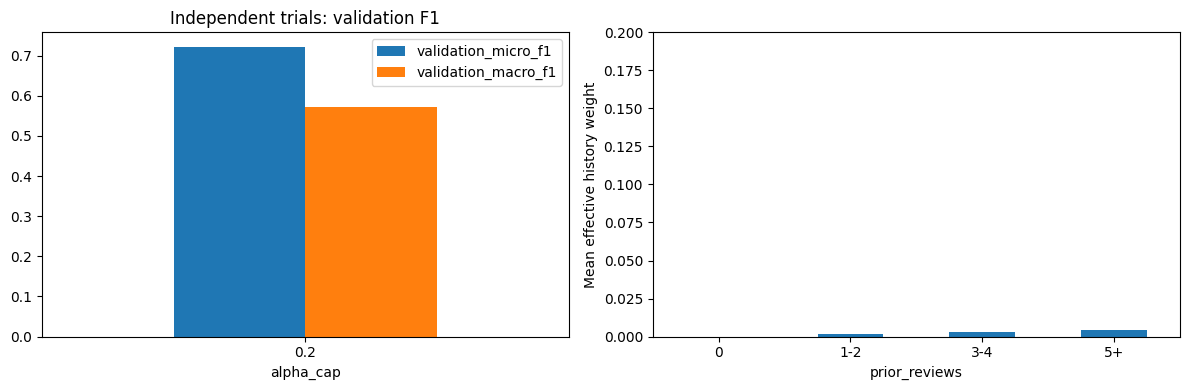

In [14]:
baseline_row=pd.read_csv(BASELINE_RUN_DIR/'comparison_row.csv')
assert len(baseline_row)==1
assert baseline_row.iloc[0]['split_fingerprint']==split_fingerprint
comparison=pd.DataFrame([
    {'experiment':'V2_text_only',**baseline_row.iloc[0].to_dict()},
    {'experiment':'V4_text_plus_history',**selected}])
columns=['experiment','validation_micro_f1','validation_macro_f1','validation_accuracy','validation_mae',
         'validation_loss','training_wall_seconds','peak_gpu_memory_gb','epochs_completed']
display(comparison[columns])
comparison.to_csv(RUN_DIR/'V2_vs_history.csv',index=False)
for key in ['validation_micro_f1','validation_macro_f1','validation_accuracy']:
    print(key,'change (percentage points):',100*(selected[key]-baseline_row.iloc[0][key]))
print('NLL in V4 and cross-entropy in V2 both refer to the negative log-probability of the true class.')
print('Three alpha trials, when enabled, are compared by validation only; total search cost exceeds the selected trial time.')

model=HistoryBertForSequenceClassification.from_pretrained(BEST_MODEL_DIR).to('cuda').eval()
from torch.utils.data import DataLoader
loader=DataLoader(tokenized_datasets['validation'],batch_size=EVAL_BATCH_SIZE,
                  collate_fn=data_collator,num_workers=0,pin_memory=True)
all_alpha=[];all_predictions=[]
with torch.inference_mode():
    for batch in loader:
        inputs={k:v.to(model.device) for k,v in batch.items() if k!='labels'}
        with torch.autocast('cuda',dtype=torch.float16):
            pooled=model.bert(input_ids=inputs['input_ids'],attention_mask=inputs['attention_mask'],
                              token_type_ids=inputs.get('token_type_ids'),return_dict=True).pooler_output
            logits=model.classifier(model.dropout(pooled))
            logp,alpha=model.mix_with_history(pooled,logits,inputs['history_features'])
        all_alpha.append(alpha.cpu().numpy());all_predictions.append(logp.argmax(-1).cpu().numpy())
alpha_values=np.concatenate(all_alpha);pred=np.concatenate(all_predictions)
assert len(pred)==len(val_df)
assert alpha_values.min()>=0 and alpha_values.max()<=selected['alpha_cap']+1e-6
assert np.all(alpha_values[val_df.past_count.to_numpy()==0]==0)
audit=pd.DataFrame({'source_row_id':val_df.source_row_id.to_numpy(),'past_count':val_df.past_count.to_numpy(),
    'past_mean':val_df.past_mean.to_numpy(),'alpha_effective':alpha_values,'actual_rating':val_df.labels.to_numpy()+1,'predicted_rating':pred+1})
audit.to_csv(RUN_DIR/'validation_history_gate_audit.csv',index=False)
groups=pd.cut(audit.past_count,bins=[-1,0,2,4,np.inf],labels=['0','1-2','3-4','5+'])
rows=[]
for label in ['0','1-2','3-4','5+']:
    part=audit.loc[groups==label]
    if len(part):
        rows.append({'prior_reviews':label,'rows':len(part),'mean_alpha':part.alpha_effective.mean(),
            'max_alpha':part.alpha_effective.max(),'accuracy':accuracy_score(part.actual_rating,part.predicted_rating),
            'macro_f1':f1_score(part.actual_rating,part.predicted_rating,labels=list(range(1,6)),average='macro',zero_division=0),
            'mae':mean_absolute_error(part.actual_rating,part.predicted_rating)})
group_report=pd.DataFrame(rows);display(group_report)
group_report.to_csv(RUN_DIR/'validation_by_history_group.csv',index=False)
# Compare original V2 predictions within exactly the same history groups, if available.
old_predictions=pd.read_csv(BASELINE_RUN_DIR/'validation_predictions.csv')
paired=audit.merge(old_predictions,on='source_row_id',how='outer',validate='one_to_one',suffixes=('_history','_V2'),indicator=True)
assert paired['_merge'].eq('both').all()
assert paired.actual_rating_history.eq(paired.actual_rating_V2).all()
paired.to_csv(RUN_DIR/'paired_V2_history_predictions.csv',index=False)

paired_groups=pd.cut(paired.past_count,bins=[-1,0,2,4,np.inf],labels=['0','1-2','3-4','5+'])
paired_rows=[]
for label in ['0','1-2','3-4','5+']:
    part=paired.loc[paired_groups==label]
    if len(part):
        old_acc=accuracy_score(part.actual_rating_V2,part.predicted_rating_V2)
        new_acc=accuracy_score(part.actual_rating_history,part.predicted_rating_history)
        paired_rows.append({'prior_reviews':label,'rows':len(part),'V2_accuracy':old_acc,
            'history_accuracy':new_acc,'delta_accuracy_percentage_points':100*(new_acc-old_acc),
            'V2_mae':mean_absolute_error(part.actual_rating_V2,part.predicted_rating_V2),
            'history_mae':mean_absolute_error(part.actual_rating_history,part.predicted_rating_history)})
paired_group_report=pd.DataFrame(paired_rows)
display(paired_group_report)
paired_group_report.to_csv(RUN_DIR/'V2_vs_history_by_group.csv',index=False)

import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4))
trials.plot.bar(x='alpha_cap',y=['validation_micro_f1','validation_macro_f1'],ax=axes[0],rot=0)
axes[0].set_title('Independent trials: validation F1')
group_report.plot.bar(x='prior_reviews',y='mean_alpha',ax=axes[1],rot=0,legend=False)
axes[1].set_ylabel('Mean effective history weight');axes[1].set_ylim(0,max(ALPHA_CAPS))
fig.tight_layout();fig.savefig(RUN_DIR/'history_and_alpha_results.png',dpi=160);plt.show()


## ۷. آزمون داخلی اختیاری؛ فقط پس از نهایی‌شدن انتخاب‌ها

RUN_TEST را فقط برای گزارش نهایی True کنید. این مدل از بانک historyِ train استفاده می‌کند؛ برچسب‌های آزمون داخلی فقط برای محاسبهٔ معیار استفاده می‌شوند. این مجموعه همان test داخلی V2 است و با test اصلی بدون overall تفاوت دارد.


In [15]:
if RUN_TEST:
    final_test=Dataset.from_pandas(test_df[['reviewText','summary','labels','past_mean','past_count']],preserve_index=False)
    final_test=final_test.map(tokenize_batch,batched=True,batch_size=256,remove_columns=['reviewText','summary'])
    eval_args=TrainingArguments(output_dir=str(LOCAL_RUN_DIR/'final_eval'),per_device_eval_batch_size=EVAL_BATCH_SIZE,
        fp16=True,report_to='none',remove_unused_columns=False,label_names=['labels'])
    final_trainer=Trainer(model=model,args=eval_args,processing_class=tokenizer,
        data_collator=data_collator,compute_metrics=compute_metrics)
    test_output=final_trainer.predict(final_test,metric_key_prefix='test')
    (RUN_DIR/'test_metrics.json').write_text(json.dumps(test_output.metrics,indent=2))
    display(pd.DataFrame([test_output.metrics]))
else:
    print('Internal test remains disabled. Alpha selection used validation only.')


Internal test remains disabled. Alpha selection used validation only.


## ۸. پیش‌بینی و بارگذاری مدل ذخیره‌شده


In [16]:
def predict_rating(review_text,summary='',reviewer_id=None,review_date=None):
    if not isinstance(review_text,str) or not review_text.strip():raise ValueError('Review text is required.')
    query=pd.DataFrame({'source_row_id':[0],'user':pd.Series([reviewer_id],dtype='string')})
    query['user']=normalized_users(query['user'])
    query['day']=pd.to_datetime(pd.Series([review_date]),errors='coerce',utc=True,format='mixed').dt.floor('D')
    enriched=attach_history(query,history_bank)
    tokens=tokenize_batch({'reviewText':[review_text.strip()],'summary':['' if summary is None else str(summary)]})
    example={key:value[0] for key,value in tokens.items()}
    example.update(past_mean=float(enriched.past_mean.iloc[0]),past_count=int(enriched.past_count.iloc[0]))
    batch={key:value.to(model.device) for key,value in data_collator([example]).items()}
    model.eval()
    with torch.inference_mode():
        p=model(**batch).logits.exp()[0].cpu().numpy()
    return {'predicted_rating':int(p.argmax())+1,'past_mean':example['past_mean'],
            'past_count':example['past_count'],'probabilities':{i+1:float(v) for i,v in enumerate(p)}}

predict_rating('The headphones sound great and the battery lasts all day.')


{'predicted_rating': 5,
 'past_mean': 3.0,
 'past_count': 0,
 'probabilities': {1: 0.0016513183945789933,
  2: 0.002822013571858406,
  3: 0.012492808513343334,
  4: 0.09869184345006943,
  5: 0.8843419551849365}}

مدل منتخب در `best_model`، تنظیمات انتخاب در `selected_model.json` و تمام سقف‌ها در `alpha_trials_ranked.csv` ذخیره می‌شوند. برای inference در session جدید، فایل `history_model.py` کنار مدل را import و کلاس `HistoryBertForSequenceClassification.from_pretrained` را فراخوانی کنید؛ برای تبدیل متن همان تابع tokenize_batch این نوت‌بوک لازم است. بانک history و policy نیز کنار خروجی اجرا ذخیره شده‌اند. AutoModel عمومی به‌تنهایی کلاس سفارشی و قواعد تاریخ/head-tail را بازسازی نمی‌کند.

حالت search به سه آموزش مستقل نیاز دارد و ممکن است از زمان یک session رایگان بیشتر شود؛ حالت پیش‌فرض فقط یک آموزش دارد. هر trial کامل، بهترین مدل و گزارش‌هایش را در Drive ذخیره می‌کند؛ این نوت‌بوک به‌صورت خودکار آموزش نیمه‌تمام را resume نمی‌کند. فایل مدل همه trialها برای بررسی باقی می‌ماند ولی checkpointهای optimizer پس از تکمیل هر trial پاک می‌شوند.

[Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer) و [merge_asof با شرط strict](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html) مراجع رابط پیاده‌سازی‌اند. برای نسبت دادن اختلاف کوچک به history، تکرار دو نسخه با seedهای یکسان بیشتر لازم است.
